In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
df = pd.read_csv("../dataset/Student_performance_data _.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [7]:
df.shape

(2392, 15)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


In [9]:
df.isnull()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2388,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2389,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2390,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["GradeClass"].value_counts().sort_index()


GradeClass
0.0     107
1.0     269
2.0     391
3.0     414
4.0    1211
Name: count, dtype: int64

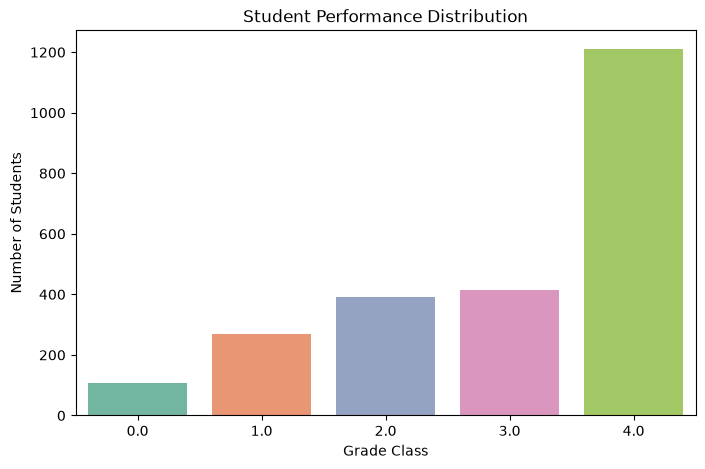

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="GradeClass",
    hue="GradeClass",
    palette="Set2",
    legend=False
)

plt.title("Student Performance Distribution")
plt.xlabel("Grade Class")
plt.ylabel("Number of Students")
plt.show()

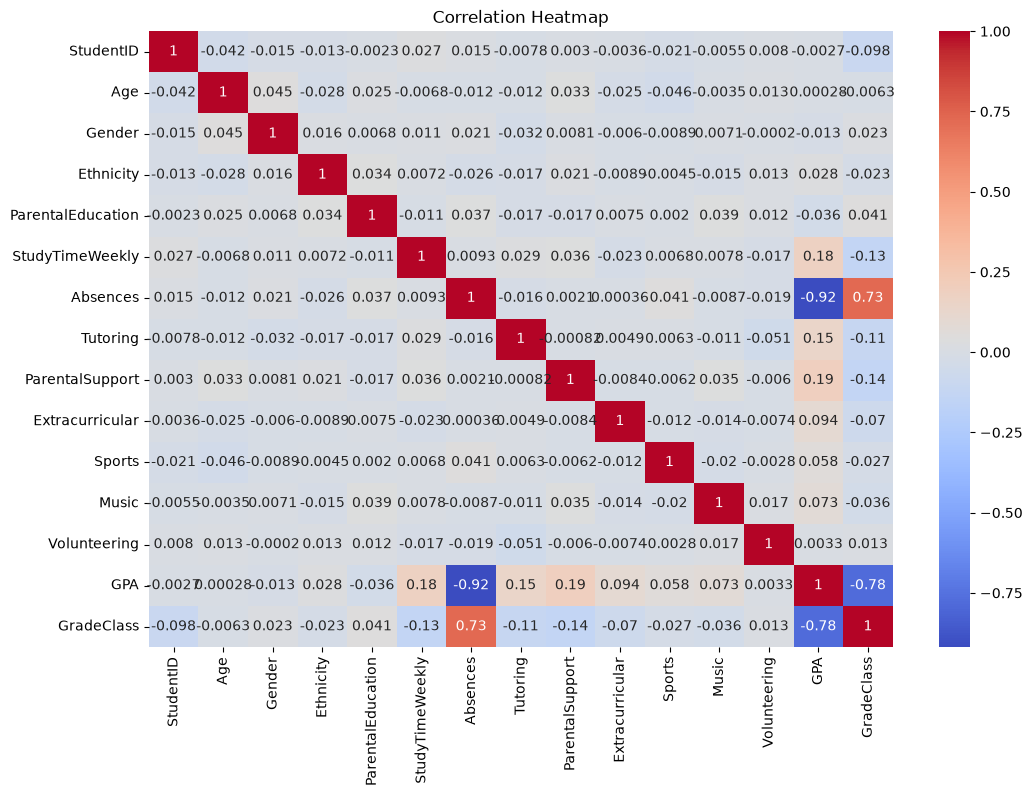

In [13]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [15]:
X = df.drop(columns=["StudentID", "GPA", "GradeClass"])

y = df["GradeClass"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Input features:
['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']

Target variable:
GradeClass


In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2392, 12)
y shape: (2392,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1913, 12)
Testing data: (479, 12)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1913, 12)
Testing data: (479, 12)


In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [20]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[4. 4. 4. 4. 1. 3. 2. 4. 4. 4.]


In [21]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 71.39874739039665 %


In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.36      0.19      0.25        21
         1.0       0.52      0.41      0.46        54
         2.0       0.51      0.65      0.57        78
         3.0       0.52      0.53      0.52        83
         4.0       0.92      0.91      0.91       243

    accuracy                           0.71       479
   macro avg       0.57      0.54      0.54       479
weighted avg       0.71      0.71      0.71       479



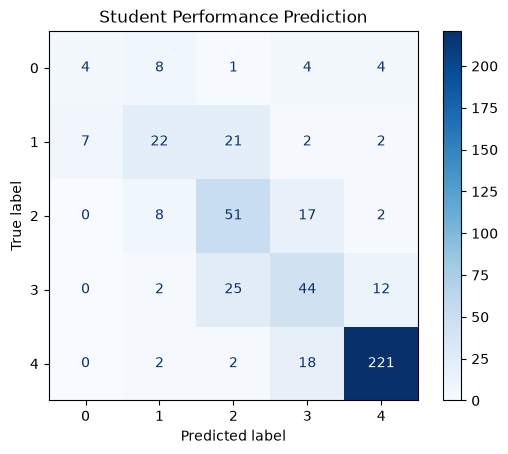

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")
plt.title("Student Performance Prediction")
plt.show()

In [24]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

              Feature  Importance
5            Absences    0.445940
4     StudyTimeWeekly    0.169229
7     ParentalSupport    0.067602
3   ParentalEducation    0.058419
0                 Age    0.056716
2           Ethnicity    0.050163
1              Gender    0.029938
9              Sports    0.028644
8     Extracurricular    0.027146
6            Tutoring    0.024481
10              Music    0.021976
11       Volunteering    0.019746


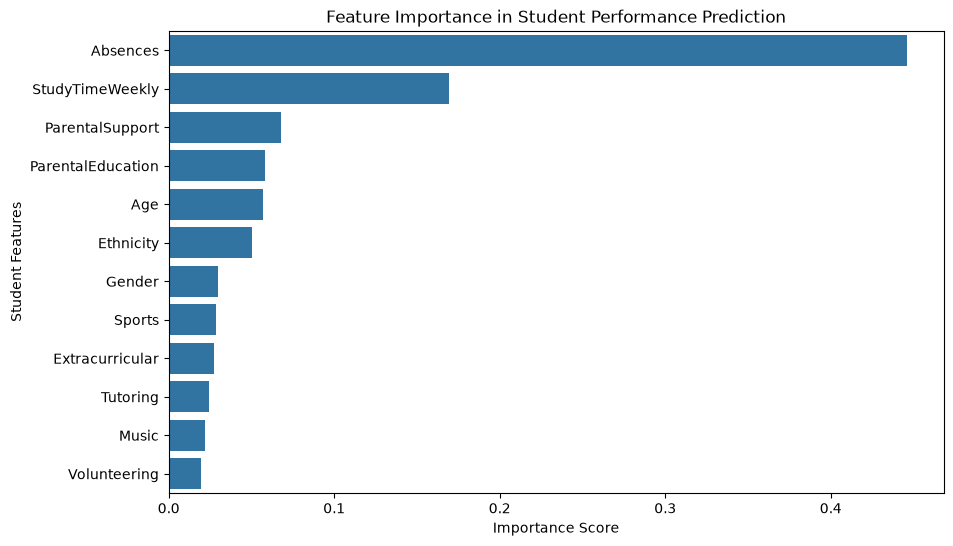

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Student Performance Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Student Features")
plt.show()

In [26]:
import joblib

joblib.dump(model, "../src/student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [27]:
import joblib

# Load the saved model
loaded_model = joblib.load("../src/student_performance_model.pkl")

# Select one student from test data
student = X_test.iloc[[0]]

# Predict performance
prediction = loaded_model.predict(student)

print("Predicted Grade Class:", prediction[0])
print("Actual Grade Class:", y_test.iloc[0])

Predicted Grade Class: 4.0
Actual Grade Class: 4.0


In [28]:
def predict_student(age, gender, ethnicity,
                    parental_education, study_time,
                    absences, tutoring, parental_support,
                    extracurricular, sports, music, volunteering):

    student_data = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Ethnicity": ethnicity,
        "ParentalEducation": parental_education,
        "StudyTimeWeekly": study_time,
        "Absences": absences,
        "Tutoring": tutoring,
        "ParentalSupport": parental_support,
        "Extracurricular": extracurricular,
        "Sports": sports,
        "Music": music,
        "Volunteering": volunteering
    }])

    prediction = loaded_model.predict(student_data)

    return prediction[0]

In [29]:
result = predict_student(
    17, 1, 0, 2, 10,
    5, 1, 3, 1, 1, 0, 0
)

print("Predicted Grade Class:", result)

Predicted Grade Class: 1.0


In [30]:
results = pd.DataFrame({
    "Actual Grade": y_test,
    "Predicted Grade": y_pred
})

results.to_csv("../reports/prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [31]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 71.39874739039665 %


In [32]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

         0.0       0.36      0.19      0.25        21
         1.0       0.52      0.41      0.46        54
         2.0       0.51      0.65      0.57        78
         3.0       0.52      0.53      0.52        83
         4.0       0.92      0.91      0.91       243

    accuracy                           0.71       479
   macro avg       0.57      0.54      0.54       479
weighted avg       0.71      0.71      0.71       479



In [33]:
report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../reports/classification_report.csv"
)

print("Classification report saved successfully!")

Classification report saved successfully!
